# Overview
1. PSO for linear regression with elasticnet (2 hyperparameters to search)
2. GA on the same data and problem
3. SA on the same data and problem
1. PSO for MLP on housing data (revisit MLP and cover the active coding, include feature processing) 

## Setup

In [66]:
# setup
import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.metrics import mean_squared_error as MSE
from sklearn.model_selection import KFold, cross_val_score, train_test_split

In [2]:
!pip install -q pyswarms


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [18]:
# the package for swarm algorithm
import pyswarms as ps

In [4]:
!pip install -q geneticalgorithm


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [19]:
# the package for genetic algorithm
from geneticalgorithm import geneticalgorithm as ga

In [36]:
# the package for simulated annealing 
from scipy.optimize import dual_annealing

## 1. PSO for Linear Regression Hyperparameters Optimization

### Data Import

In [76]:
data = pd.read_csv('https://github.com/yanhai-xiong/DATA301-AML/blob/main/Data%20Sets/concrete.csv?raw=true')

In [77]:
x = data.loc[:,'cement':'age'].values
y = data['strength'].values

In [9]:
# data = pd.read_csv('https://github.com/yanhai-xiong/DATA301-AML/blob/main/Data%20Sets/AirI.csv?raw=true', header=None)

In [27]:
data.head(3)

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27


In [11]:
y = data.iloc[:,0].values
x = data.iloc[:,1:].values

In [28]:
kf = KFold(n_splits=5,shuffle=True,random_state=123)
scale = StandardScaler()

### Objective Format for PSO

The objective function is an assignment between a choice of hyperparameters and a corresponding prediction error.

#### ElasticNet Regression

ElasticNet combines **L1 (Lasso)** and **L2 (Ridge)** regularization to reduce overfitting.

```python
model = ElasticNet(alpha=a, l1_ratio=l, fit_intercept=True, max_iter=50000)
```

**Objective Function:**

$$
\min_{\mathbf{w},b}\;
\frac{1}{2n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
+\alpha l\sum_{j=1}^{p}|w_j|
+\frac{\alpha(1-l)}{2}\sum_{j=1}^{p}w_j^2
$$

**Parameters:**
- `alpha=a`: Overall regularization strength (larger values mean stronger regularization).
- `l1_ratio=l`: Balance between L1 and L2 penalties:
  - `l=1`: Lasso (L1), encourages feature selection.
  - `l=0`: Ridge (L2), shrinks coefficients without typically eliminating them.
  - `0<l<1`: Combination of L1 and L2.
- `fit_intercept=True`: Learn the intercept (bias).
- `max_iter=50000`: Maximum solver iterations for convergence.

**PSO Goal:** Find the best combination of `alpha` and `l1_ratio` that minimizes cross-validation MSE.


In [14]:
# the format of the objective function for Particle Swarm Optimization
# use ElasticNet linear regression model
def objective_pso(h):
  output = []
  for i in range(h.shape[0]):
    a = h[i,0]
    l = h[i,1]
    model = ElasticNet(alpha=a,l1_ratio=l,fit_intercept=True,max_iter=50000)
    PE = []
    for idxtrain, idxtest in kf.split(x):
      xtrain = x[idxtrain]
      ytrain = y[idxtrain]
      xtrain = scale.fit_transform(xtrain)
      xtest = x[idxtest]
      ytest = y[idxtest]
      xtest = scale.transform(xtest)
      model.fit(xtrain,ytrain)
      PE.append(MSE(ytest,model.predict(xtest)))
    output.append(np.mean(PE))
  return output

In [15]:
# set a list of hyperparameters to check obj computation
h = np.array([[0.01,0.2],[0.25,0.4],[0.3,0.15]])

In [29]:
objective_pso(h)

[110.28963379668588, 117.39571870760817, 121.83676508407957]

In [ ]:
# objective with ElasticNet linear regression model and polynomial features
def objective_pso_poly(h):
  output = []
  for i in range(h.shape[0]):
    a = h[i,0]
    l = h[i,1]
    model = ElasticNet(alpha=a,l1_ratio=l,max_iter=50000)
    scale = StandardScaler()
    poly = PolynomialFeatures(degree=2)
    pipe = Pipeline([['Poly Feats',poly],['scaler',scale]]) # different data processing here
    PE = []
    for idxtrain, idxtest in kf.split(x):
      xtrain = x[idxtrain]
      ytrain = y[idxtrain]
      xtrain = pipe.fit_transform(xtrain)
      xtest = x[idxtest]
      ytest = y[idxtest]
      xtest = pipe.transform(xtest)
      model.fit(xtrain,ytrain)
      PE.append(MSE(ytest,model.predict(xtest)))
    output.append(np.mean(PE))
  return output

### The Application of PSO

```python
optimizer = ps.single.GlobalBestPSO(n_particles=20, dimensions=2, options=options, bounds=bounds)
cost, pos = optimizer.optimize(objective_pso, iters=150)
```

**1. Initialize the swarm**
- `GlobalBestPSO`: All particles share the best solution found by the entire swarm.
- `n_particles=20`: Create 20 particles, each representing a candidate solution.
- `dimensions=2`: Each particle has 2 variables (e.g., $x_1, x_2$).
- `options`: PSO hyperparameters:
  - `w`: Inertia weight (maintains previous velocity).
  - `c1`: Cognitive coefficient (attraction toward personal best).
  - `c2`: Social coefficient (attraction toward global best).
- `bounds`: Lower and upper limits for each variable.

**2. Run optimization**
- `objective_pso`: Objective function to minimize. Takes all particle positions (shape `(20, 2)`) and returns 20 loss values.
- `iters=150`: Repeat the optimization process 150 times.
- At each iteration, particles evaluate their losses, update personal/global best positions, and adjust their velocities and positions.
- **Total evaluations**: $20 \times 150 = 3000$ candidate solutions.

**3. Return results**
- `cost`: Lowest loss found across all particles and iterations.
- `pos`: Best particle position (an array of 2 optimized variable values).

**Key Idea:** Unlike gradient descent, PSO does not require gradients. Particles explore the search space by learning from their own best positions and the swarm's global best.


In [32]:
# instantiate the optimizer
max_b = np.array([2,1])
min_b = np.array([0.001,0.001])
bounds = (min_b, max_b)
options = {'c1': 2, 'c2': 2, 'w': 0.6}

optimizer = ps.single.GlobalBestPSO(n_particles=20, dimensions=2, options=options, bounds=bounds)
cost, pos = optimizer.optimize(objective_pso, iters=150)

2026-11-03 15:48:01,060 - pyswarms.single.global_best - INFO - Optimize for 150 iters with {'c1': 2, 'c2': 2, 'w': 0.6}
pyswarms.single.global_best: 100%|██████████████████████|150/150, best_cost=110
2026-11-03 15:48:11,747 - pyswarms.single.global_best - INFO - Optimization finished | best cost: 110.14511278878904, best pos: [0.10073286 0.99353973]


In [33]:
# now the poly version
max_b = np.array([4,1])
min_b = np.array([0,0])
bounds = (min_b, max_b)
options = {'c1': 2, 'c2': 2, 'w': 0.5}
optimizer = ps.single.GlobalBestPSO(n_particles=20, dimensions=2, options=options, bounds=bounds)
cost, pos = optimizer.optimize(objective_pso_poly, iters=100)

2026-11-03 15:48:32,393 - pyswarms.single.global_best - INFO - Optimize for 100 iters with {'c1': 2, 'c2': 2, 'w': 0.5}
pyswarms.single.global_best: 100%|█████████████████████|100/100, best_cost=59.5
2026-11-03 15:48:59,977 - pyswarms.single.global_best - INFO - Optimization finished | best cost: 59.48530359777094, best pos: [0.0010624  0.61746946]


## 2. GA on the same dataset

In [34]:
# this is the format for the Genetic Algorithm and SKLearn Simmulated Annealing
def objective(h):
  a = h[0]
  l = h[1]
  model = ElasticNet(alpha=a,l1_ratio=l,fit_intercept=True,max_iter=50000)
  PE = []
  scale = StandardScaler()
  pipe = Pipeline([['Scale',scale]])

  # uncomment the below to switch to poly version
  #poly = PolynomialFeatures(degree=2)
  #pipe = Pipeline([['Polynomial Features',poly],['Scale',scale]])
    
  for idxtrain, idxtest in kf.split(x):
    xtrain = x[idxtrain]
    ytrain = y[idxtrain]
    xtrain = pipe.fit_transform(xtrain)
    xtest = x[idxtest]
    ytest = y[idxtest]
    xtest = pipe.transform(xtest)
    model.fit(xtrain,ytrain)
    PE.append(MSE(ytest,model.predict(xtest)))
  return np.mean(PE)

 The best solution found:                                                                           
 [0.09863563 0.9917702 ]

 Objective function:
 110.14895308898777


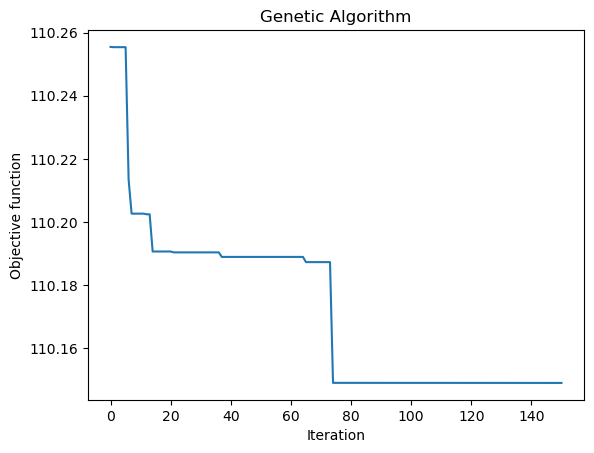

In [35]:
varbound=np.array([[0,2],[0,1]])

model=ga(function=objective,dimension=2,variable_type='real',variable_boundaries=varbound)

model.run()

## 3. SA on the same dataset

Dual Annealing is an advanced variant of Simulated Annealing (SA).(`scipy.optimize.dual_annealing`)

Unlike standard Simulated Annealing, Dual Annealing uses a generalized acceptance probability:
$$
P(\text{accept}) =
\begin{cases}
1, & \Delta E \leq 0 \\[6pt]
\left[1+(q_a-1)\dfrac{\Delta E}{T}\right]^{\frac{1}{q_a-1}}, & \Delta E>0 \text{ and } 1+(q_a-1)\dfrac{\Delta E}{T}>0 \\[6pt]
0, & \text{otherwise}
\end{cases}
$$
where:
- $\Delta E = \text{New Loss} - \text{Current Loss}$
- $T$: Current temperature.
- $q_a = \texttt{accept}$ (default: $-5.0$).

**Interpretation:**
- Better solutions ($\Delta E \leq 0$) are always accepted.
- Worse solutions may be accepted to escape local minima.
- More negative `accept` values reduce the probability of accepting worse solutions.
- Allowed range: $-10^4 \leq q_a \leq -5$.


**Example:**
```python
ret = dual_annealing(objective, bounds=list(zip(lw, up)))
```

**Important Parameters:**
- `func`: Objective function to minimize (takes one candidate solution at a time).
- `bounds`: Lower and upper limits for each variable (required).
- `maxiter=1000`: Maximum number of global search iterations.
- `initial_temp=5230.0`: Initial temperature controlling exploration.
- `visit=2.62`: Controls the distribution of search jumps (larger values encourage longer jumps; range: $1 < visit \leq 3$).
- `accept=-5.0`.
- `no_local_search=False`: Enables local optimization by default; set to `True` to disable it.

**Output (`ret`):**
- `ret.x`: Best solution (optimized variable values).
- `ret.fun`: Minimum objective function value found.
- `ret.nfev`: Total number of objective function evaluations.


In [37]:
lw = [0.00001,0.00001]
up = [2,1]
ret = dual_annealing(objective, bounds=list(zip(lw, up)))

In [38]:
ret.x

array([0.10373796, 1.        ])

In [39]:
ret

 message: ['Maximum number of iteration reached']
 success: True
  status: 0
     fun: 110.13939096662804
       x: [ 1.037e-01  1.000e+00]
     nit: 1000
    nfev: 4190
    njev: 63
    nhev: 0

### Simulated Annealing from Scratch for RandomForestRegressor

In [40]:
h_names = ['n_estimators','max_depth']

In [55]:
model = RandomForestRegressor()

In [ ]:
def GS_Anneal(model, h_names, h1, h2):
    # Simulated Annealing for two hyperparameters
    STEP_SIZE = 12
    COOLING = 0.9

    def cost_function(model):
        pipe = Pipeline([ ('Scale', StandardScaler()), ('Model', model) ])
        scores = cross_val_score(estimator=pipe, X=x, y=y, cv=3, scoring='neg_mean_squared_error'
        )
        return -scores.mean()

    def random_start():
        i = np.random.randint(0, len(h1))
        j = np.random.randint(0, len(h2))
        return [i, j]

    def random_neighbour(pos, T):
        # Generate Gaussian steps
        delta_i = int(np.round(np.random.normal() * STEP_SIZE * T))
        delta_j = int(np.round(np.random.normal() * STEP_SIZE * T))

        # Ensure the indices remain valid
        new_i = np.clip(pos[0] + delta_i, 0, len(h1) - 1)
        new_j = np.clip(pos[1] + delta_j, 0, len(h2) - 1)

        return [int(new_i), int(new_j)]

    def acceptance_probability(cost, new_cost, T):
        if new_cost <= cost:
            return 1.0
        return np.exp(-(new_cost - cost) / T)

    def annealing():
        pos = random_start()
        def evaluate(pos):
            model.set_params(**{
                h_names[0]: h1[pos[0]],
                h_names[1]: h2[pos[1]]
            })
            return cost_function(model)

        cost = evaluate(pos)

        # Track the best solution separately
        best_pos = pos.copy()
        best_cost = cost
        states = [[h1[pos[0]], h2[pos[1]]]]
        costs = [cost]
        best_costs = [best_cost]
        T = 1.0
        while T > 1e-10:
            new_pos = random_neighbour(pos, T)
            new_cost = evaluate(new_pos)

            if acceptance_probability(cost, new_cost, T) > np.random.random():
                pos = new_pos
                cost = new_cost
                states.append([h1[pos[0]], h2[pos[1]]])
                costs.append(cost)

            if new_cost < best_cost:
                best_cost = new_cost
                best_pos = new_pos.copy()

            best_costs.append(best_cost)
            T *= COOLING

        # Restore the best hyperparameters
        model.set_params(**{
            h_names[0]: h1[best_pos[0]],
            h_names[1]: h2[best_pos[1]]
        })
        return np.array(states), costs, best_costs, best_pos, best_cost

    states, costs, best_costs, best_pos, best_cost = annealing()
    print("Best hyperparameters:", {
        h_names[0]: h1[best_pos[0]],
        h_names[1]: h2[best_pos[1]]
    })
    print("Best CV MSE:", best_cost)
    return states, costs, best_costs

In [86]:
h1 = [10, 50]  # Number of trees
h2 = [10, 20]    # Maximum tree depth

results = []

# Run Simulated Annealing 3 times
for i in range(3):
    states, costs, best_costs = GS_Anneal(model, h_names, h1, h2)
    results.append((np.min(best_costs), states, costs, best_costs))
    print(f"Run {i+1}: Best MSE = {np.min(best_costs):.4f}")

# Select the run with the lowest MSE
best_cost, states, costs, best_costs = sorted(results, key=lambda r: r[0])[0]

print("\nOverall Best MSE:", best_cost)

Best hyperparameters: {'n_estimators': 10, 'max_depth': 20}
Best CV MSE: 110.85436789879672
Run 1: Best MSE = 110.8544
Best hyperparameters: {'n_estimators': 10, 'max_depth': 10}
Best CV MSE: 113.79206648632403
Run 2: Best MSE = 113.7921
Best hyperparameters: {'n_estimators': 10, 'max_depth': 10}
Best CV MSE: 112.04583307483308
Run 3: Best MSE = 112.0458

Overall Best MSE: 110.85436789879672


## 4. PSO for MLP on housing data 
Revisit MLP and cover the active coding problem from Module 4, include feature processing

In [ ]:
data_housing = pd.read_csv('https://github.com/yanhai-xiong/DATA301-AML/blob/main/Data%20Sets/housing.csv?raw=true')

print(data_housing.shape)
print(data_housing.dtypes)
print(data_housing.isnull().sum())
display(data_housing.head())

### Data Preprocessing for MLP Regression

- **Target:** `cmedv` (median housing value).
- **Categorical features:** Convert `river` into numerical values; exclude `town` and `tract` for simplicity.
- **Missing values:** Replace missing numerical values using training-set medians.
- **Data splitting:** Training (60%), validation (20%), testing (20%).
- **Standardization:** Scale features to approximately zero mean and unit variance. Also scale the target to improve neural network training.
- **Avoid data leakage:** Fit preprocessing transformations on the training set only.

The validation set is used for PSO hyperparameter optimization; the test set is reserved for final evaluation.


In [68]:
import torch
import torch.nn as nn

In [78]:
# Features and target
X_house = data_housing.drop(columns=['cmedv', 'town', 'tract']).copy()
X_house['river'] = X_house['river'].map({'no': 0, 'yes': 1})
X_house = X_house.apply(pd.to_numeric, errors='coerce')

y_house = data_housing['cmedv'].to_numpy(dtype=np.float32)

# Split: 60% training, 20% validation, 20% testing
X_train, X_temp, y_train, y_temp = train_test_split(X_house, y_house, test_size=0.4, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Impute missing values using training medians
medians = X_train.median()
X_train = X_train.fillna(medians)
X_val = X_val.fillna(medians)
X_test = X_test.fillna(medians)

# Standardize features
x_scaler = StandardScaler()
X_train = x_scaler.fit_transform(X_train)
X_val = x_scaler.transform(X_val)
X_test = x_scaler.transform(X_test)

# Standardize target
y_scaler = StandardScaler()
y_train = y_scaler.fit_transform(y_train.reshape(-1, 1))
y_val = y_scaler.transform(y_val.reshape(-1, 1))
y_test = y_scaler.transform(y_test.reshape(-1, 1))

# Convert to PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_val = torch.tensor(X_val, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: torch.Size([303, 14])
Validation: torch.Size([101, 14])
Testing: torch.Size([102, 14])


In [79]:
class HousingMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x):
        return self.net(x)

In [80]:
def train_model(lr, hidden_dim, epochs=150, seed=42):

    # Reproducible model initialization
    torch.manual_seed(seed)

    model = HousingMLP(
        input_dim=X_train.shape[1],
        hidden_dim=hidden_dim
    )

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for epoch in range(epochs):
        model.train()

        optimizer.zero_grad()
        predictions = model(X_train)
        loss = criterion(predictions, y_train)

        loss.backward()
        optimizer.step()

    # Evaluate on validation set
    model.eval()
    with torch.no_grad():
        val_predictions = model(X_val)
        val_loss = criterion(val_predictions, y_val).item()

    return val_loss, model

### PSO Objective Function
Each particle specifies two hyperparameters:
- `h[i, 0]`: $\log_{10}(\text{learning rate})$, searched between $-4$ and $-2$.
- `h[i, 1]`: Number of hidden neurons, searched between 8 and 64.

For each particle:
1. Create a new MLP with the specified hyperparameters.
2. Train the MLP on the training set.
3. Calculate validation MSE.
4. Return the validation MSE as the particle's cost.

**Goal:** Find the hyperparameters that minimize validation MSE.

In [81]:
def objective_pso(h):
    costs = []

    for i in range(h.shape[0]):
        lr = 10 ** h[i, 0]
        hidden_dim = int(np.clip(np.round(h[i, 1]), 8, 64))

        val_loss, _ = train_model(
            lr=lr,
            hidden_dim=hidden_dim,
            epochs=150
        )

        costs.append(val_loss)

    return np.array(costs)

In [82]:
options = {'c1': 1.5, 'c2': 1.5, 'w': 0.7}

bounds = (
    np.array([-4.0, 8.0]),
    np.array([-2.0, 64.0])
)

optimizer = ps.single.GlobalBestPSO(
    n_particles=8,
    dimensions=2,
    options=options,
    bounds=bounds
)

cost, pos = optimizer.optimize(
    objective_pso,
    iters=15
)

best_lr = 10 ** pos[0]
best_hidden = int(np.clip(np.round(pos[1]), 8, 64))

print("Best learning rate:", best_lr)
print("Best hidden neurons:", best_hidden)
print("Best validation MSE (scaled):", cost)

2026-11-03 16:55:15,526 - pyswarms.single.global_best - INFO - Optimize for 15 iters with {'c1': 1.5, 'c2': 1.5, 'w': 0.7}
pyswarms.single.global_best: 100%|█████████████████████|15/15, best_cost=0.0669
2026-11-03 16:55:18,489 - pyswarms.single.global_best - INFO - Optimization finished | best cost: 0.0668925940990448, best pos: [-2.44895131 58.16778822]


Best learning rate: 0.0035567119377313853
Best hidden neurons: 58
Best validation MSE (scaled): 0.0668925940990448


# Practical Guide: Choosing GA, PSO, or SA for Hyperparameter Optimization

All three algorithms are **gradient-free, stochastic optimization methods**. The choice depends on the **hyperparameter type, computational cost, search-space size, and parallelization**.

#### 1. Comparison

| | Genetic Algorithm (GA) | Particle Swarm Optimization (PSO) | Simulated Annealing (SA) |
|---|---|---|---|
| **Best suited for** | Discrete, categorical, mixed | Continuous | Discrete or continuous |
| **Search strategy** | Population + crossover/mutation | Swarm + velocity updates | Single solution + random neighbors |
| **Parallelization** | Excellent | Excellent | Limited |
| **Strength** | Flexible for different parameter types | Efficient for low-dimensional continuous search | Simple, low memory usage |
| **Limitation** | Many model evaluations | Premature convergence | Sequential search; sensitive to cooling schedule |

#### 2. Adapting to Different Hyperparameter Types

- **Continuous** (e.g., learning rate, regularization strength):
  - **GA:** Represent parameters as real-valued genes; use continuous crossover and mutation.
  - **PSO:** Directly optimize particle positions within continuous bounds.
  - **SA:** Generate neighboring solutions using Gaussian perturbations.

- **Discrete/Integer** (e.g., number of layers, number of trees):
  - **GA:** Use integer-valued genes with discrete mutation/crossover.
  - **PSO:** Round particle positions to valid integer values.
  - **SA:** Move between neighboring integer values (e.g., $n \rightarrow n \pm 1$).

- **Categorical** (e.g., activation function, optimizer type):
  - **GA:** Encode categories as genes and use categorical mutation.
  - **PSO:** Requires categorical/discrete encoding or a specialized PSO variant; simple rounding may create artificial ordering.
  - **SA:** Randomly switch between valid categories.

**Note:** For parameters spanning several orders of magnitude (e.g., learning rate), optimize in log space: $z=\log_{10}(\text{lr})$.

#### 3. Concrete ML Examples

| ML Model | Hyperparameters | Suggested Algorithm |
|---|---|---|
| ElasticNet | `alpha`, `l1_ratio` (continuous) | **PSO** |
| Random Forest | `n_estimators`, `max_depth` (integer) | **GA or SA** |
| MLP | Learning rate, weight decay (continuous) | **PSO** |
| MLP | Hidden neurons, number of layers (integer) | **GA or SA** |
| CNN | Number of layers, kernel sizes, activation functions | **GA** |
| CNN | Learning rate, dropout rate (continuous) | **PSO** |
| CNN | Mixed architecture and training hyperparameters | **GA** |

#### 4. Practical Recommendations

- **Choose GA** for mixed/discrete search spaces, especially neural network architecture optimization.
- **Choose PSO** for continuous hyperparameters, especially with a small number of dimensions.
- **Choose SA** for sequential neighborhood search when maintaining a population is unnecessary.
- **For expensive model training:** Consider Bayesian optimization, random search, or Hyperband to reduce expensive evaluations.
- **For small search spaces:** Grid Search may be simpler and more reliable.

**Important:** GA and PSO evaluate populations, while SA typically evaluates one candidate at a time. Compare algorithms using the **same number of objective function evaluations**, not the same number of iterations.

**Key Takeaway:** Hyperparameter type helps determine the algorithm, but **computational budget, search efficiency, and parallelization** are equally important.
